# Data import
What datasets are you using, later explain the variables a little bit more


In [1]:
import pandas as pd
import os
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder


In [2]:
print("Current Working Directory:", os.getcwd())


# Load the datasets
mat_data = pd.read_csv('../../student/student-mat.csv', sep=';')
por_data = pd.read_csv('../../student/student-por.csv', sep=';')

# View the first few rows
print(mat_data.head())
print(por_data.head())

Current Working Directory: c:\Users\ivoga\Documents\Git local repositories\projekt-R\testiranje\klasifikacijski_modeli\combined
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5       

In [3]:
print(mat_data.describe())
print(por_data.describe())

              age        Medu        Fedu  traveltime   studytime    failures  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean    16.696203    2.749367    2.521519    1.448101    2.035443    0.334177   
std      1.276043    1.094735    1.088201    0.697505    0.839240    0.743651   
min     15.000000    0.000000    0.000000    1.000000    1.000000    0.000000   
25%     16.000000    2.000000    2.000000    1.000000    1.000000    0.000000   
50%     17.000000    3.000000    2.000000    1.000000    2.000000    0.000000   
75%     18.000000    4.000000    3.000000    2.000000    2.000000    0.000000   
max     22.000000    4.000000    4.000000    4.000000    4.000000    3.000000   

           famrel    freetime       goout        Dalc        Walc      health  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean     3.944304    3.235443    3.108861    1.481013    2.291139    3.554430   
std      0.896659    0.9988

# Encoding the data
binary features are encoded using label encoding (0 and 1), 
while for categorical features one-hot encoding is used.
As for the numerical features, they are normilized using min-max scaling.

In [4]:
# combine the data
combined_data = pd.concat([mat_data, por_data], ignore_index=True)

In [5]:
# encoding the binary features
binary_features = ['school', 'sex', 'address', 'famsize', 'Pstatus', 
                   'schoolsup', 'famsup', 'paid', 'activities', 
                   'nursery', 'higher', 'internet', 'romantic']

label_encoder = LabelEncoder()
for feature in binary_features:
    combined_data[feature] = label_encoder.fit_transform(combined_data[feature])


# one-hot endocing the categorical features
categorical_features = ['Mjob', 'Fjob', 'reason', 'guardian']

combined_data = pd.get_dummies(combined_data, columns=categorical_features, drop_first=True)

# normalizing numeric features using min-max scaling
numeric_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 
                    'failures', 'famrel', 'freetime', 'goout', 'Dalc', 
                    'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

scaler = MinMaxScaler()
combined_data[numeric_features] = scaler.fit_transform(combined_data[numeric_features])



# Outlier Detection and Removal
Using IQR method to identify and remove outliers in numeric features

In [6]:
for col in numeric_features:
    Q1 = combined_data[col].quantile(0.25)
    Q3 = combined_data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    combined_data = combined_data[(combined_data[col] >= lower_bound) & (combined_data[col] <= upper_bound)]

# Binary Classification
Predict whether G3 is above or below a threshold (e.g., 0.5)


In [7]:
# Create a binary target variable
combined_data['G3_binary'] = (combined_data['G3'] > 0.5).astype(int)

# Define features and target
X_binary = combined_data.drop(columns=['G3', 'G3_binary'])
y_binary = combined_data['G3_binary']

In [8]:
# Split the data
X_train_binary, X_test_binary, y_train_binary, y_test_binary = train_test_split(
    X_binary, y_binary, test_size=0.2, random_state=42
)


In [9]:
# Train Logistic Regression Model
lr_binary = LogisticRegression(max_iter=1000, random_state=42)
lr_binary.fit(X_train_binary, y_train_binary)

LogisticRegression(max_iter=1000, random_state=42)

Binary Classification Results:
Accuracy: 0.904
Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.79      0.79        28
           1       0.94      0.94      0.94        97

    accuracy                           0.90       125
   macro avg       0.86      0.86      0.86       125
weighted avg       0.90      0.90      0.90       125

Confusion Matrix:
[[22  6]
 [ 6 91]]


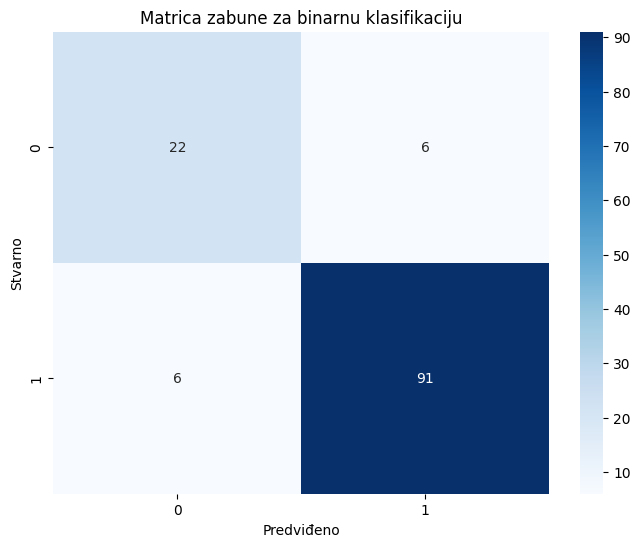

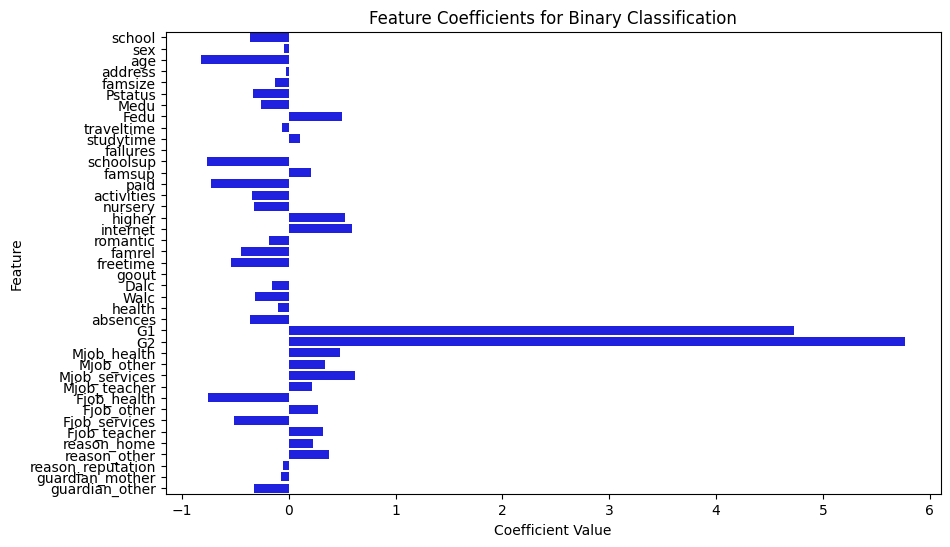

In [18]:
# Predict and evaluate
y_pred_binary = lr_binary.predict(X_test_binary)
print("Binary Classification Results:")
print(f"Accuracy: {accuracy_score(y_test_binary, y_pred_binary)}")
print("Classification Report:")
print(classification_report(y_test_binary, y_pred_binary))
print("Confusion Matrix:")
print(confusion_matrix(y_test_binary, y_pred_binary))

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_binary, y_pred_binary), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predviđeno")
plt.ylabel("Stvarno")
plt.title("Matrica zabune za binarnu klasifikaciju")
plt.show()

# Visualize coefficients
coefficients_binary = lr_binary.coef_[0]
feature_names_binary = X_binary.columns

plt.figure(figsize=(10, 6))
sns.barplot(x=coefficients_binary, y=feature_names_binary, color="b")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.title("Feature Coefficients for Binary Classification")
plt.show()

In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, log_loss

# Binary Classification
print("Binary Classification Results:")
print(f"Accuracy: {accuracy_score(y_test_binary, y_pred_binary)}")
print(f"Precision: {precision_score(y_test_binary, y_pred_binary)}")
print(f"Recall: {recall_score(y_test_binary, y_pred_binary)}")
print(f"F1-Score: {f1_score(y_test_binary, y_pred_binary)}")
print(f"AUC-ROC: {roc_auc_score(y_test_binary, y_pred_binary)}")

# Log-Loss (use predicted probabilities)
y_pred_prob_binary = lr_binary.predict_proba(X_test_binary)[:, 1]
print(f"Log-Loss: {log_loss(y_test_binary, y_pred_prob_binary)}")

Binary Classification Results:
Accuracy: 0.904
Precision: 0.9381443298969072
Recall: 0.9381443298969072
F1-Score: 0.9381443298969072
AUC-ROC: 0.8619293078055964
Log-Loss: 0.2879244318348435


# 5-Level Classification
Categorize G3 into 5 performance levels

In [12]:
# Create 5 levels for the target variable (G3)
combined_data['G3_5_levels'] = pd.cut(
    combined_data['G3'],
    bins=5,
    labels=[0, 1, 2, 3, 4],
    include_lowest=True
)

In [13]:
# Define features and target
X_5_levels = combined_data.drop(columns=['G3', 'G3_binary', 'G3_5_levels'])
y_5_levels = combined_data['G3_5_levels']

In [14]:
# Split the data
X_train_5, X_test_5, y_train_5, y_test_5 = train_test_split(
    X_5_levels, y_5_levels, test_size=0.2, random_state=42
)

In [15]:
# Train Logistic Regression Model
lr_5_levels = LogisticRegression(max_iter=1000, multi_class='multinomial', random_state=42)
lr_5_levels.fit(X_train_5, y_train_5)

c:\Users\ivoga\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(max_iter=1000, multi_class='multinomial', random_state=42)

5-Level Classification Results:
Accuracy: 0.576
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.11      0.20         9
           1       0.60      0.84      0.70        37
           2       0.58      0.32      0.42        34
           3       0.55      0.80      0.65        35
           4       0.50      0.10      0.17        10

    accuracy                           0.58       125
   macro avg       0.64      0.43      0.43       125
weighted avg       0.60      0.58      0.53       125

Confusion Matrix:
[[ 1  8  0  0  0]
 [ 0 31  4  2  0]
 [ 0 10 11 13  0]
 [ 0  3  3 28  1]
 [ 0  0  1  8  1]]


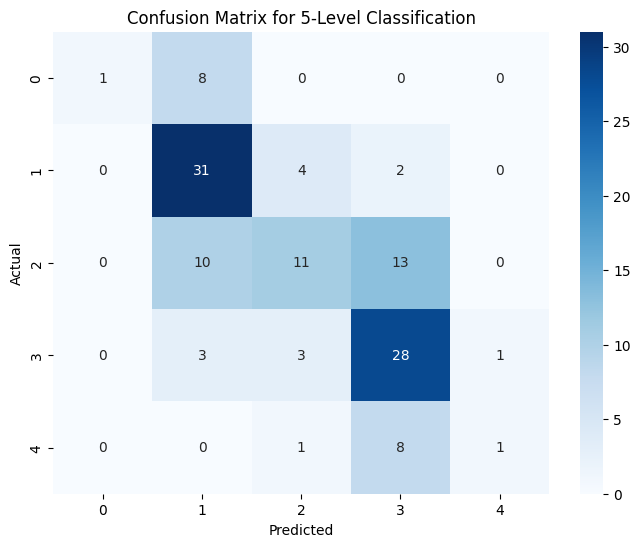

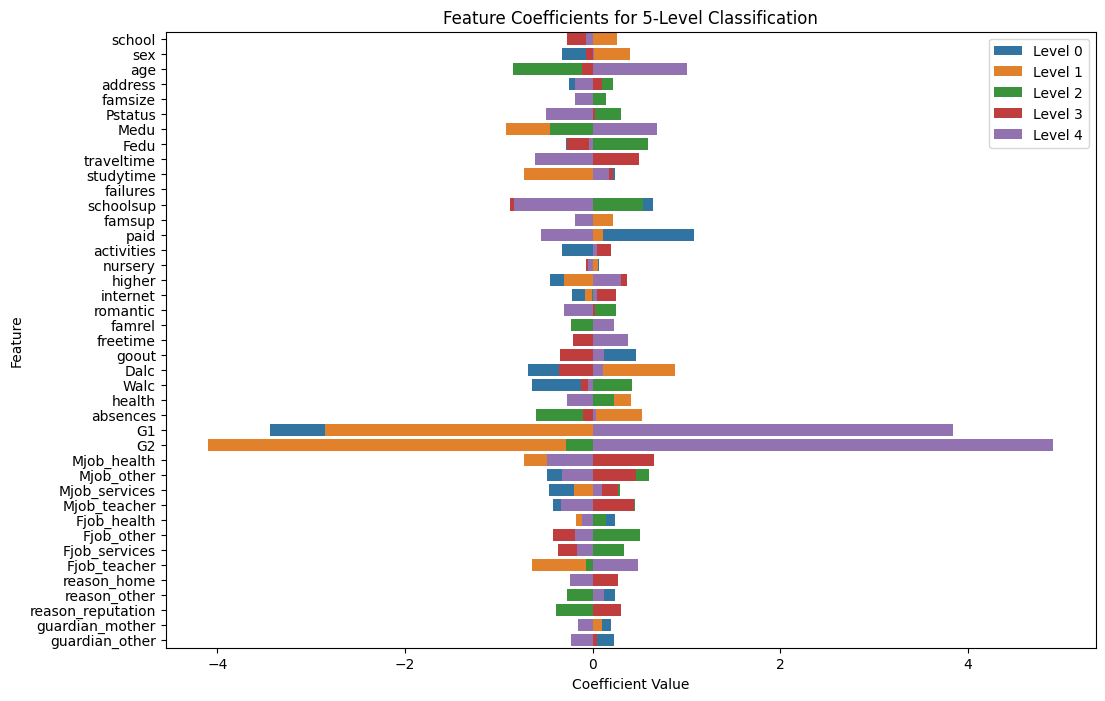

In [ ]:
# Predict and evaluate
y_pred_5 = lr_5_levels.predict(X_test_5)
print("5-Level Classification Results:")
print(f"Accuracy: {accuracy_score(y_test_5, y_pred_5)}")
print("Classification Report:")
print(classification_report(y_test_5, y_pred_5))
print("Confusion Matrix:")
print(confusion_matrix(y_test_5, y_pred_5))

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_5, y_pred_5), annot=True, fmt="d", cmap="Blues", 
            xticklabels=[0, 1, 2, 3, 4], yticklabels=[0, 1, 2, 3, 4])
plt.xlabel("Predviđeno")
plt.ylabel("Stvarno")
plt.title("Matrica zabune za klasifikaciju na 5 razina")
plt.show()

# Visualize coefficients
coefficients_5_levels = lr_5_levels.coef_
feature_names_5_levels = X_5_levels.columns

plt.figure(figsize=(12, 8))
for i in range(coefficients_5_levels.shape[0]):
    sns.barplot(x=coefficients_5_levels[i], y=feature_names_5_levels, label=f"Level {i}")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.title("Feature Coefficients for 5-Level Classification")
plt.legend()
plt.show()


In [17]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
from sklearn.preprocessing import label_binarize

# Convert the labels to a binary format for AUC-ROC
y_test_5_bin = label_binarize(y_test_5, classes=[0, 1, 2, 3, 4])
y_pred_5_bin = label_binarize(y_pred_5, classes=[0, 1, 2, 3, 4])

# 5-Level Classification
print("5-Level Classification Results:")
print(f"Accuracy: {accuracy_score(y_test_5, y_pred_5)}")
print(f"Precision (Macro): {precision_score(y_test_5, y_pred_5, average='macro')}")
print(f"Recall (Macro): {recall_score(y_test_5, y_pred_5, average='macro')}")
print(f"F1-Score (Macro): {f1_score(y_test_5, y_pred_5, average='macro')}")
print(f"AUC-ROC (Micro): {roc_auc_score(y_test_5_bin, y_pred_5_bin, average='micro', multi_class='ovr')}")

# Log-Loss (use predicted probabilities)
y_pred_prob_5 = lr_5_levels.predict_proba(X_test_5)
log_loss_5 = log_loss(y_test_5, y_pred_prob_5)
print(f"Log-Loss: {log_loss_5}")

5-Level Classification Results:
Accuracy: 0.576
Precision (Macro): 0.6448241644836072
Recall (Macro): 0.434495672142731
F1-Score (Macro): 0.42591060209402576
AUC-ROC (Micro): 0.7350000000000001
Log-Loss: 1.0553811725663726
